In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (r2_score, mean_absolute_error,mean_squared_error, mean_absolute_percentage_error,confusion_matrix, ConfusionMatrixDisplay, accuracy_score)
from sklearn.model_selection import cross_val_score, KFold

# **Load and Inspect Data**

In [2]:
df=pd.read_csv('Car_details_v3.csv')
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [4]:
df.shape

(8128, 13)

In [5]:
df.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [6]:
df.isna().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

In [7]:
# Check Duplicates
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
8123    False
8124    False
8125    False
8126     True
8127     True
Length: 8128, dtype: bool

In [8]:
# Remove Duplicates
df=df.drop_duplicates()
df.shape

(6926, 13)

In [9]:
# Check Columns
cols=df.columns
cols

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque',
       'seats'],
      dtype='str')

In [10]:
# take numerical columns
num_cols=df.select_dtypes(include=[np.number]).columns.to_list()
num_cols

['year', 'selling_price', 'km_driven', 'seats']

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6926 non-null   str    
 1   year           6926 non-null   int64  
 2   selling_price  6926 non-null   int64  
 3   km_driven      6926 non-null   int64  
 4   fuel           6926 non-null   str    
 5   seller_type    6926 non-null   str    
 6   transmission   6926 non-null   str    
 7   owner          6926 non-null   str    
 8   mileage        6718 non-null   str    
 9   engine         6718 non-null   str    
 10  max_power      6721 non-null   str    
 11  torque         6717 non-null   str    
 12  seats          6718 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 757.5 KB


In [12]:
str_cols = df.select_dtypes(include=['object', 'string']).columns
str_cols

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage',
       'engine', 'max_power', 'torque'],
      dtype='str')

In [13]:
df['name'].value_counts(dropna=False)

name
Maruti Swift Dzire VDI                          118
Maruti Alto 800 LXI                              76
Maruti Alto LXi                                  69
Maruti Swift VDI                                 60
Maruti Swift VDI BSIV                            56
                                               ... 
Maruti Celerio ZXI AMT BSIV                       1
Tata Bolt Revotron XM                             1
Tata Manza Aura (ABS) Safire BS IV                1
Tata Nexon 1.5 Revotorq XT                        1
Toyota Innova 2.5 GX (Diesel) 8 Seater BS IV      1
Name: count, Length: 2058, dtype: int64

In [14]:
df['fuel'].value_counts(dropna=False)

fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64

In [15]:
df['seller_type'].value_counts(dropna=False)

seller_type
Individual          6218
Dealer               681
Trustmark Dealer      27
Name: count, dtype: int64

In [16]:
df['transmission'].value_counts(dropna=False)

transmission
Manual       6342
Automatic     584
Name: count, dtype: int64

In [17]:
df['owner'].value_counts(dropna=False)

owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: int64

In [18]:
df['mileage'].value_counts(dropna=False)

mileage
18.9 kmpl     210
NaN           208
19.7 kmpl     168
18.6 kmpl     150
21.1 kmpl     146
             ... 
11.3 kmpl       1
15.1 km/kg      1
14.21 kmpl      1
11.72 kmpl      1
16.51 kmpl      1
Name: count, Length: 394, dtype: int64

In [19]:
df[['fuel','mileage']].value_counts(dropna=False)

fuel    mileage   
Petrol  18.9 kmpl     210
        19.7 kmpl     164
        18.6 kmpl     147
        21.1 kmpl     118
Diesel  15.96 kmpl    108
                     ... 
CNG     15.1 km/kg      1
Diesel  14.21 kmpl      1
Petrol  21.7 kmpl       1
Diesel  11.72 kmpl      1
Petrol  16.51 kmpl      1
Name: count, Length: 486, dtype: int64

In [20]:
df['engine'].value_counts(dropna=False)

engine
1248 CC    907
1197 CC    698
796 CC     421
998 CC     398
2179 CC    339
          ... 
2650 CC      1
2446 CC      1
3498 CC      1
2776 CC      1
1950 CC      1
Name: count, Length: 122, dtype: int64

In [21]:
df['max_power'].value_counts(dropna=False)

max_power
74 bhp       324
NaN          205
88.5 bhp     177
46.3 bhp     158
67 bhp       152
            ... 
194 bhp        1
60.2 bhp       1
134 bhp        1
203 bhp        1
135.1 bhp      1
Name: count, Length: 323, dtype: int64

In [22]:
df['torque'].value_counts(dropna=False)

torque
190Nm@ 2000rpm            472
200Nm@ 1750rpm            398
90Nm@ 3500rpm             353
NaN                       209
62Nm@ 3000rpm             160
                         ... 
250.06nm@ 1500-2750rpm      1
90nm@ 3500rpm               1
190Nm@ 3700rpm              1
436.4Nm@ 1800-2500rpm       1
96  Nm at 3000  rpm         1
Name: count, Length: 442, dtype: int64

# **EDA**

                Target  Skewness
   selling_price (raw)      5.57
log(1 + selling_price)     -0.16


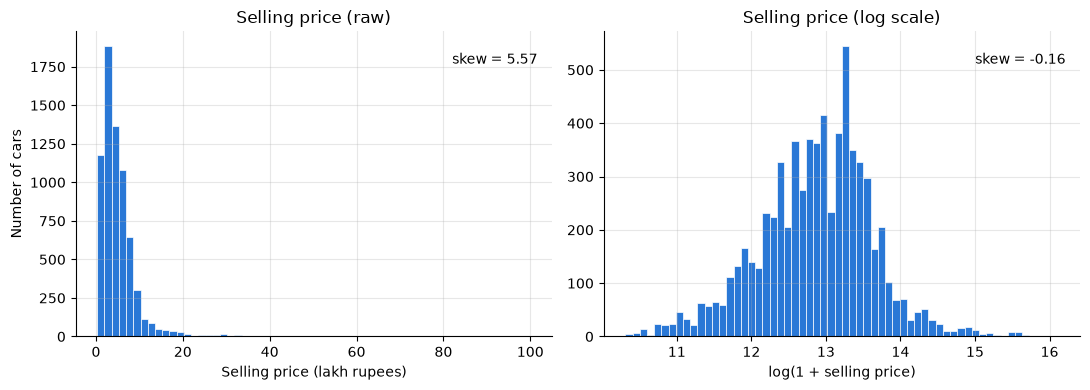

In [23]:
# Price distribution
df["log_price"] = np.log1p(df["selling_price"])

# Skewness values (these go in your caption and table)
skew_raw = df["selling_price"].skew()
skew_log = df["log_price"].skew()
print(pd.DataFrame({
    "Target": ["selling_price (raw)", "log(1 + selling_price)"],
    "Skewness": [round(skew_raw, 2), round(skew_log, 2)],
}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["selling_price"] / 1e5, bins=60, color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[0].set_title("Selling price (raw)")
axes[0].set_xlabel("Selling price (lakh rupees)")
axes[0].set_ylabel("Number of cars")
axes[0].text(0.97, 0.93, f"skew = {skew_raw:.2f}", transform=axes[0].transAxes, ha="right", va="top")

axes[1].hist(df["log_price"], bins=60, color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[1].set_title("Selling price (log scale)")
axes[1].set_xlabel("log(1 + selling price)")
axes[0].set_ylabel("Number of cars")
axes[1].text(0.97, 0.93, f"skew = {skew_log:.2f}", transform=axes[1].transAxes, ha="right", va="top")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


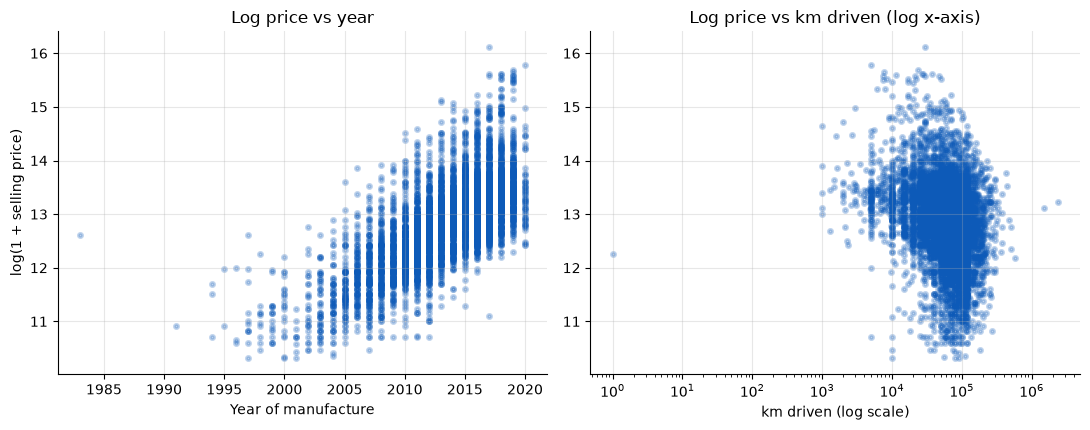

In [24]:
# Price vs year and km driven
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

axes[0].scatter(df["year"], df["log_price"], s=9, alpha=0.25, color="#0d5ab8", linewidths=2)
axes[0].set_title("Log price vs year")
axes[0].set_xlabel("Year of manufacture")
axes[0].set_ylabel("log(1 + selling price)")

axes[1].scatter(df["km_driven"].clip(lower=1), df["log_price"], s=9, alpha=0.25, color="#0d5ab8", linewidths=2)
axes[1].set_xscale("log")
axes[1].set_title("Log price vs km driven (log x-axis)")
axes[1].set_xlabel("km driven (log scale)")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

          median     n
fuel                  
CNG     320000.0    56
Diesel  520000.0  3755
LPG     195500.0    38
Petrol  310000.0  3077 

                median     n
transmission                
Automatic     850000.0   584
Manual        385000.0  6342 



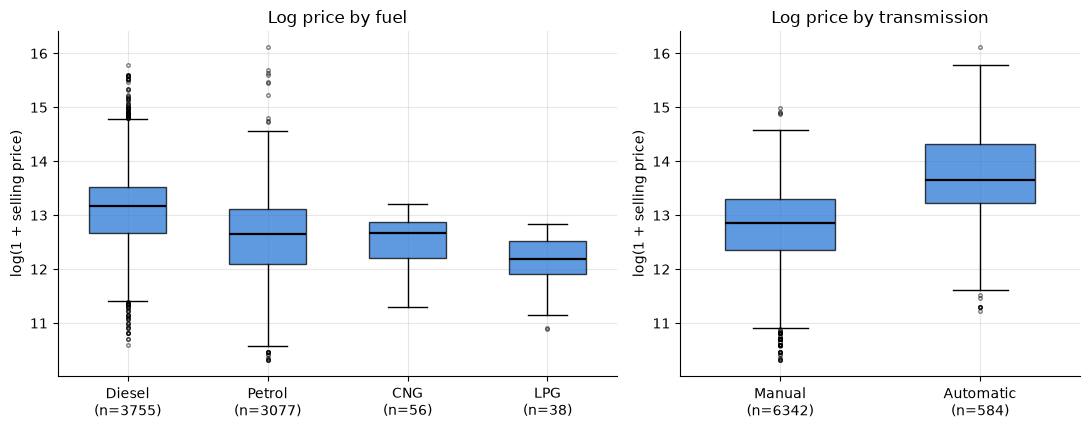

In [25]:
# Price by fuel and transmission
for col in ["fuel", "transmission"]:
    print(df.groupby(col)["selling_price"].agg(median="median", n="count"), "\n")

def box_by(ax, col, order):
    data = [df.loc[df[col] == k, "log_price"].values for k in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                    medianprops=dict(color="black", linewidth=1.6),
                    flierprops=dict(marker="o", markersize=2.5, alpha=0.5))
    for box in bp["boxes"]:
        box.set_facecolor("#2a78d6"); box.set_alpha(0.75)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels([f"{k}\n(n={len(d)})" for k, d in zip(order, data)])
    ax.set_ylabel("log(1 + selling price)")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
box_by(axes[0], "fuel", ["Diesel", "Petrol", "CNG", "LPG"]);  axes[0].set_title("Log price by fuel")
box_by(axes[1], "transmission", ["Manual", "Automatic"]);     axes[1].set_title("Log price by transmission")

plt.tight_layout()
plt.show()

In [26]:
# Outlier
# Counts for the table
q1, q3 = df["km_driven"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("IQR upper fence (km):", upper)
print("km_driven above fence:", (df["km_driven"] > upper).sum())
print("km_driven > 300,000:", (df["km_driven"] > 300_000).sum())
print("km_driven > 500,000:", (df["km_driven"] > 500_000).sum())
print("km_driven <= 1:", (df["km_driven"] <= 1).sum())
print("year < 2000:", (df["year"] < 2000).sum())
print("price > 50 lakh:", (df["selling_price"] > 5_000_000).sum())

# Inspect the extremes before deciding
print(df.sort_values("km_driven", ascending=False).head(10)[["name", "year", "km_driven", "selling_price"]])

IQR upper fence (km): 190000.0
km_driven above fence: 167
km_driven > 300,000: 18
km_driven > 500,000: 3
km_driven <= 1: 1
year < 2000: 48
price > 50 lakh: 20
                                               name  year  km_driven  \
3486                           Hyundai i20 Asta 1.2  2007    2360457   
1810                         Mahindra XUV500 W6 2WD  2012    1500000   
3508                       Maruti Wagon R LXI Minor  2010     577414   
6673  Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII  2011     500000   
3641                       Maruti Wagon R VXI BS IV  2011     500000   
5106                          Mahindra Scorpio M2DI  2011     475000   
5189         Toyota Innova 2.5 VX (Diesel) 7 Seater  2013     440000   
5467   Toyota Innova 2.5 VX (Diesel) 7 Seater BS IV  2010     426000   
2272                            Mahindra Bolero SLE  2010     380000   
7102            Toyota Innova 2.5 V Diesel 8-seater  2007     376412   

      selling_price  
3486         550000  
1810

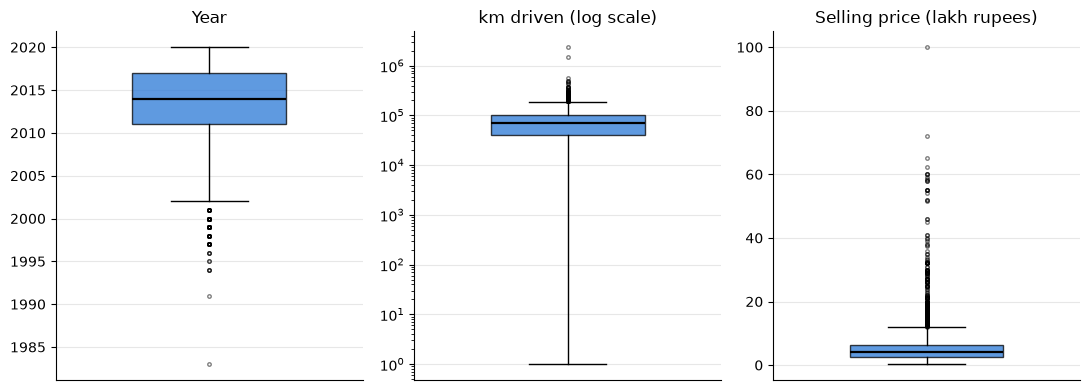

In [27]:
# Boxplots
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
panels = [("Year", df["year"]),
          ("km driven (log scale)", df["km_driven"].clip(lower=1)),
          ("Selling price (lakh rupees)", df["selling_price"] / 1e5)]
for ax, (title, values) in zip(axes, panels):
    bp = ax.boxplot(values, patch_artist=True, widths=0.5,
                    medianprops=dict(color="black", linewidth=1.6),
                    flierprops=dict(marker="o", markersize=2.5, alpha=0.5))
    bp["boxes"][0].set_facecolor("#2a78d6"); bp["boxes"][0].set_alpha(0.75)
    ax.set_title(title); ax.set_xticks([])
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()


# **Data Cleaning**

In [28]:
# Change Mileaga
df['mileage_num'] = df['mileage'].str.extract(r'([\d.]+)')[0].astype(float)
mask = df['mileage'].str.contains('km/kg', na=False)  
df.loc[mask, 'mileage_num'] = df.loc[mask, 'mileage_num'] / 1.47
df['mileage'] = df['mileage_num'].round(2)
df = df.drop(columns='mileage_num')
df['mileage'].value_counts(dropna=False)

mileage
18.90    210
NaN      208
19.70    168
18.60    150
21.10    146
        ... 
11.30      1
10.27      1
14.21      1
11.72      1
16.51      1
Name: count, Length: 391, dtype: int64

In [29]:
df[['fuel','mileage']].value_counts(dropna=False)

fuel    mileage
Petrol  18.90      210
        19.70      164
        18.60      147
        21.10      118
Diesel  15.96      108
                  ... 
CNG     10.27        1
Diesel  14.21        1
Petrol  21.70        1
Diesel  11.72        1
Petrol  16.51        1
Name: count, Length: 486, dtype: int64

In [30]:
# NaN mileage per fuel type
df[df['mileage'].isna()]['fuel'].value_counts()

fuel
Petrol    104
Diesel     97
CNG         4
LPG         3
Name: count, dtype: int64

In [31]:
# Zero mileage per fuel type
df[df['mileage'] == 0]['fuel'].value_counts()

fuel
Petrol    10
Diesel     5
Name: count, dtype: int64

In [32]:
# Convert 0 and NaN value with median
df['mileage'] = df['mileage'].replace(0, np.nan)
df['mileage'] = df['mileage'].fillna(df.groupby('fuel')['mileage'].transform('median'))
df['mileage'].isna().sum()

np.int64(0)

In [33]:
# sey engine float into engine_cc
df['engine_cc'] = df['engine'].str.extract(r'([\d.]+)')[0].astype(float)

In [34]:
# Check 'engine' NaN value
df['engine_cc'].isna().sum()

np.int64(208)

In [35]:
# Check 'engine' 0 value
(df['engine_cc'] == 0).sum()

np.int64(0)

In [36]:
# convert nan value with median
df['engine_cc'] = df['engine_cc'].fillna(df.groupby('name')['engine_cc'].transform('median'))
# 2. median of the same brand + fuel
df['engine_cc'] = df['engine_cc'].fillna(df.groupby('fuel')['engine_cc'].transform('median'))
# check
df['engine_cc'].isna().sum()

np.int64(0)

In [37]:
# Check max power and replace nan
df['max_power_bhp'] = df['max_power'].str.extract(r'([\d.]+)')[0].astype(float)
df['max_power_bhp'].isna().sum()

np.int64(206)

In [38]:
# Check 'max_power' 0 value
(df['max_power_bhp'] == 0).sum()

np.int64(3)

In [39]:
df['max_power_bhp'] = df['max_power_bhp'].replace(0, np.nan)
df['max_power_bhp'] = df['max_power_bhp'].fillna(df.groupby('name')['max_power_bhp'].transform('median'))
df['max_power_bhp'] = df['max_power_bhp'].fillna(df.groupby(['fuel', 'engine_cc'])['max_power_bhp'].transform('median'))
df['max_power_bhp'] = df['max_power_bhp'].fillna(df.groupby('fuel')['max_power_bhp'].transform('median'))

In [40]:
df['max_power_bhp'].isna().sum()

np.int64(0)

In [41]:
# Check 'max_power' 0 value
(df['max_power_bhp'] == 0).sum()

np.int64(0)

In [47]:
# Check seats
df['seats'].isna().sum()

np.int64(208)

In [48]:
(df['seats'] == 0).sum()

np.int64(0)

In [50]:
# Replace nan values in seats
df['seats'] = df['seats'].fillna(
    df.groupby('name')['seats'].transform(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan)
)
df['seats'].isna().sum()

np.int64(152)

In [51]:
df['seats'] = df['seats'].fillna(df['seats'].mode()[0])
df['seats'].isna().sum()

np.int64(0)

# **Feature Engineering**

In [53]:
ref_year = df['year'].max()
df['car_age'] = ref_year - df['year']

# 2. brand from the car name (first word)
df['brand'] = df['name'].str.split().str[0]
df['brand'] = df['brand'].replace({'Land': 'Land Rover', 'Ashok': 'Ashok Leyland'})

# 3. group rare brands (fewer than 20 cars) into "Other"
counts = df['brand'].value_counts()
df['brand_grouped'] = df['brand'].where(df['brand'].map(counts) >= 20, 'Other')

# 4. target: log of price (price is heavily skewed)
df['log_price'] = np.log(df['selling_price'])
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,log_price,engine_cc,max_power_bhp,car_age,brand,brand_grouped
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,13.017003,1248.0,74.00,6,Maruti,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,12.821258,1498.0,103.52,6,Skoda,Skoda
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,11.970350,1497.0,78.00,14,Honda,Honda
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,12.323856,1396.0,90.00,10,Hyundai,Hyundai
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,11.775290,1298.0,88.20,13,Maruti,Maruti


In [59]:
X_base = pd.get_dummies(df[['year', 'km_driven', 'fuel', 'transmission']], drop_first=True)

# Engineered: car_age + brand
X_eng = pd.get_dummies(df[['car_age', 'km_driven', 'fuel', 'transmission', 'brand_grouped']], drop_first=True)

y = df['log_price']
print(X_base.shape, X_eng.shape)   

(6926, 6) (6926, 24)


In [60]:
df['km_per_year'] = df['km_driven'] / (df['car_age'] + 1)

# **Test Train Split**

In [61]:
train_idx, test_idx = train_test_split(
    df.index, test_size=0.2, random_state=42
)
y_train = y.loc[train_idx]
y_test  = y.loc[test_idx]

# baseline features
Xb_train = X_base.loc[train_idx]
Xb_test  = X_base.loc[test_idx]

# engineered features
Xe_train = X_eng.loc[train_idx]
Xe_test  = X_eng.loc[test_idx]

price_test = df.loc[test_idx, 'selling_price']

# check
print(Xb_train.shape, Xb_test.shape)
print(Xe_train.shape, Xe_test.shape)
print(len(y_train), len(y_test))

(5540, 6) (1386, 6)
(5540, 24) (1386, 24)
5540 1386


# **Train Model**

## **Train LinearRegression Model**

In [62]:
lr_base = LinearRegression()
lr_base.fit(Xb_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 0.12,-0. , 0.4 ,-0.19,-0.09,-0.74]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['year','km_driven','fuel_Diesel','fuel_LPG','fuel_Petrol', 'transmission_Manual']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-231.6
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [65]:
# ---------- Engineered features ----------
lr_eng = LinearRegression()
lr_eng.fit(Xe_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](24,)","[-0.12,-0. , 0.34,...,-0.57, 0.38,-0.17]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](24,)","['car_age','km_driven','fuel_Diesel',...,'brand_grouped_Tata', 'brand_grouped_Toyota','brand_grouped_Volkswagen']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.13
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,24
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(22)


In [70]:
pred_lr_base = lr_base.predict(Xb_test)
pred_lr_eng  = lr_eng.predict(Xe_test)
price_pred_lr_base = np.exp(pred_lr_base)
price_pred_lr_eng  = np.exp(pred_lr_eng)

In [72]:
print(lr_base.score(Xb_train, y_train))

0.6812585357028029


## **Train RandomForestRegressor Model**

In [64]:
rf_base = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_base.fit(Xb_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [66]:
# ---------- Engineered features ----------
rf_eng = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_eng.fit(Xe_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [71]:

pred_rf_base = rf_base.predict(Xb_test)
pred_rf_eng  = rf_eng.predict(Xe_test)
price_pred_rf_base = np.exp(pred_rf_base)
price_pred_rf_eng  = np.exp(pred_rf_eng)

In [75]:

print(rf_base.score(Xb_train, y_train))

0.8278877634277286


# **Model Evaluation**

In [76]:
def evaluate(name, y_true_log, y_pred_log):
    # metrics in rupees (convert back from log)
    y_true = np.exp(y_true_log)
    y_pred = np.exp(y_pred_log)
    return {
        'Model': name,
        'R2 (log price)': r2_score(y_true_log, y_pred_log),
        'R2 (rupees)':    r2_score(y_true, y_pred),
        'MAE (Rs)':       mean_absolute_error(y_true, y_pred),
        'RMSE (Rs)':      np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)':       mean_absolute_percentage_error(y_true, y_pred) * 100,
    }

results = pd.DataFrame([
    evaluate('Linear Regression | baseline',   y_test, pred_lr_base),
    evaluate('Random Forest | baseline',       y_test, pred_rf_base),
    evaluate('Linear Regression | engineered', y_test, pred_lr_eng),
    evaluate('Random Forest | engineered',     y_test, pred_rf_eng),
]).set_index('Model')

print(results.round(3))

                                R2 (log price)  R2 (rupees)    MAE (Rs)  \
Model                                                                     
Linear Regression | baseline             0.670        0.467  163170.558   
Random Forest | baseline                 0.649        0.445  166884.042   
Linear Regression | engineered           0.773        0.744  131288.704   
Random Forest | engineered               0.768        0.726  131419.711   

                                 RMSE (Rs)  MAPE (%)  
Model                                                 
Linear Regression | baseline    341751.718    35.588  
Random Forest | baseline        348866.104    36.088  
Linear Regression | engineered  236994.383    28.985  
Random Forest | engineered      245156.180    28.121  


## **Confusion Matrics**

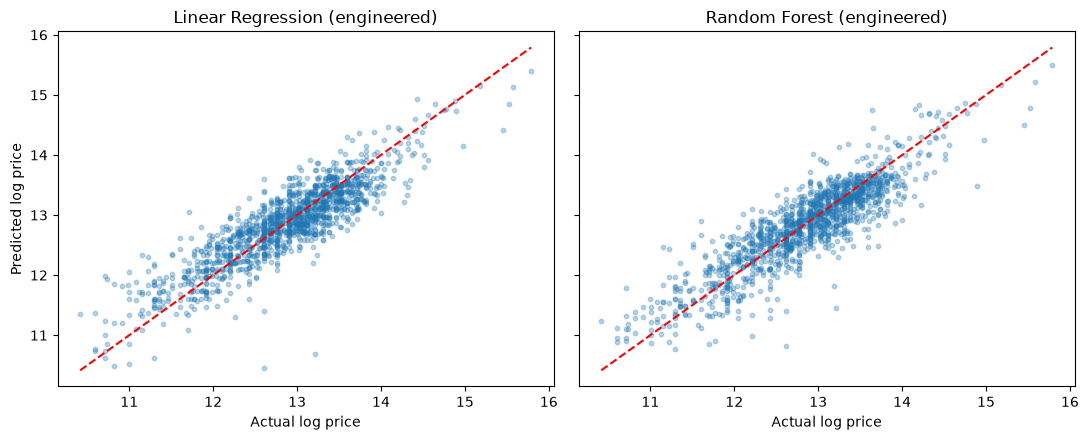

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (title, pred) in zip(axes, [('Linear Regression', pred_lr_eng),
                                    ('Random Forest', pred_rf_eng)]):
    ax.scatter(y_test, pred, alpha=0.3, s=10)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, 'r--')
    ax.set_title(f'{title} (engineered)')
    ax.set_xlabel('Actual log price')
axes[0].set_ylabel('Predicted log price')
plt.tight_layout(); 
plt.show()

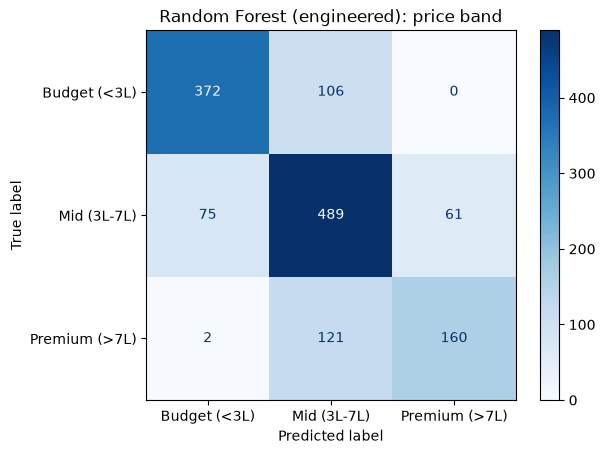

In [80]:
actual = np.exp(y_test)
bins   = [0, 300_000, 700_000, np.inf]
labels = ['Budget (<3L)', 'Mid (3L-7L)', 'Premium (>7L)']

actual_band = pd.cut(actual, bins=bins, labels=labels)
pred_band   = pd.cut(np.exp(pred_rf_eng), bins=bins, labels=labels)

cm = confusion_matrix(actual_band, pred_band, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap='Blues')
plt.title('Random Forest (engineered): price band')
plt.show()


In [81]:
lr = results.loc[['Linear Regression | baseline', 'Linear Regression | engineered']].reset_index(drop=True)
rf = results.loc[['Random Forest | baseline',     'Random Forest | engineered']].reset_index(drop=True)

compare = pd.DataFrame({
    'Feature set': ['baseline', 'engineered'],
    'R2 LR':  lr['R2 (log price)'],  'R2 RF':  rf['R2 (log price)'],
    'MAE LR': lr['MAE (Rs)'],        'MAE RF': rf['MAE (Rs)'],
    'MAPE LR (%)': lr['MAPE (%)'],   'MAPE RF (%)': rf['MAPE (%)'],
})

# how much better is Random Forest than Linear Regression?
compare['R2 gain (RF-LR)']    = compare['R2 RF'] - compare['R2 LR']
compare['MAE reduction (%)']  = (compare['MAE LR'] - compare['MAE RF']) / compare['MAE LR'] * 100

print(compare.round(3).to_string(index=False))

Feature set  R2 LR  R2 RF     MAE LR     MAE RF  MAPE LR (%)  MAPE RF (%)  R2 gain (RF-LR)  MAE reduction (%)
   baseline  0.670  0.649 163170.558 166884.042       35.588       36.088           -0.021             -2.276
 engineered  0.773  0.768 131288.704 131419.711       28.985       28.121           -0.004             -0.100


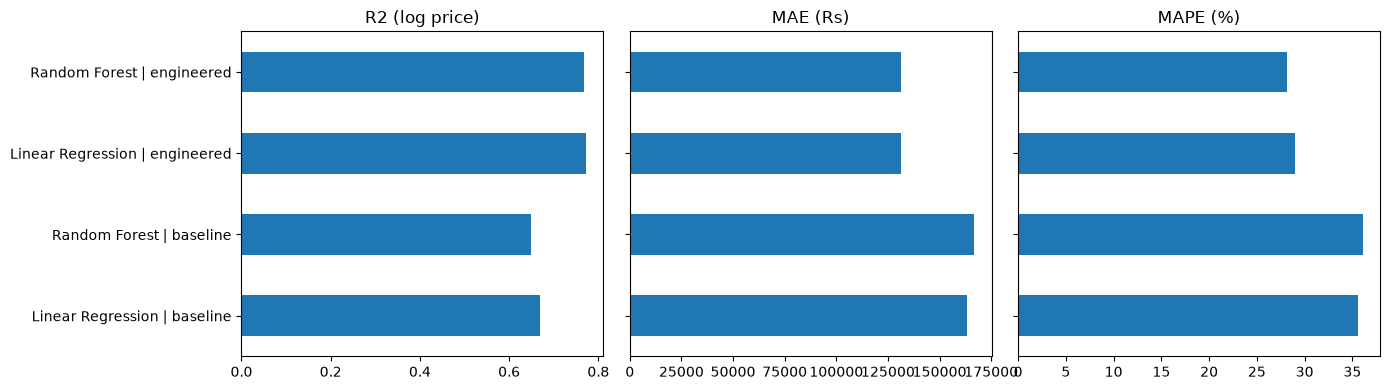

In [82]:
metrics = ['R2 (log price)', 'MAE (Rs)', 'MAPE (%)']
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, m in zip(axes, metrics):
    results[m].plot(kind='barh', ax=ax)
    ax.set_title(m)
    ax.set_ylabel('')
    if ax is not axes[0]:
        ax.set_yticklabels([])
plt.tight_layout(); plt.show()

In [84]:


cv = KFold(n_splits=5, shuffle=True, random_state=42)

lr_scores = cross_val_score(LinearRegression(), Xe_train, y_train, cv=cv, scoring='r2')
rf_scores = cross_val_score(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
                            Xe_train, y_train, cv=cv, scoring='r2')

print('LR per fold:', lr_scores.round(3))
print('RF per fold:', rf_scores.round(3))
print('RF better in', (rf_scores > lr_scores).sum(), 'of 5 folds')

LR per fold: [0.799 0.786 0.773 0.792 0.744]
RF per fold: [0.784 0.771 0.754 0.772 0.734]
RF better in 0 of 5 folds


Using only age/year, distance driven, fuel type and transmission, Linear Regression explained 67.0% of the variation in log price (MAE ≈ Rs 163,171, MAPE 35.6%), and Random Forest was slightly worse at 64.9% (MAE ≈ Rs 166,884). Adding the brand feature and the car-age variable raised R² to 0.773 for Linear Regression and 0.768 for Random Forest, and cut the MAE by about 20% and 21% respectively (to roughly Rs 131,000), so the engineered features clearly improved prediction for both models. Because car_age is only a reversal of year, this gain is attributable to brand. The two models performed almost identically on the engineered features (R² difference 0.004), and Linear Regression had the higher R² in all five cross-validation folds, so no evidence was found that Random Forest’s flexibility pays off with so few predictors. With more time I would tune the Random Forest (for example min_samples_leaf and max_features), test gradient boosting, and add engine size, power and owner type, since brand is probably a proxy for them. I would also check the largest errors, which are probably luxury cars, and the model’s age, since this dataset is a pre-2020 snapshot.